# Lesson 2: Where does `c` live? The Mandelbrot set

Lesson 1 left a question open. We watched `c` change the Julia set,
but never asked which values of `c` give a connected shape and which
shatter it into dust.

There is a picture that answers that for every `c` at once. It is the
**Mandelbrot set**, and it is best read as a *map of `c`*.

## Two planes

- The **z-plane** holds the starting points. The Julia set lives here.
- The **c-plane** holds the parameter. The Mandelbrot set lives here.

Each point in the c-plane is a different Julia set in the z-plane.
The Mandelbrot set is the c-plane colored by one question about
that Julia set.

## The question

Julia sets come in two kinds: **connected** (one piece) or **dust**
(infinitely many disconnected specks). Which kind you get depends on
one orbit, the **critical orbit** that starts at `z = 0`:

> If the orbit of 0 stays bounded, the Julia set is connected.
> If it escapes, the Julia set is dust.

So `c` is in the Mandelbrot set when the orbit of 0 under
`z -> z^2 + c` never escapes.

## Test it on two values of c

In [1]:
def orbit_of_zero(c, n=12):
    z = 0j
    path = []
    for _ in range(n):
        z = z * z + c
        path.append(z)
    return path


for c in [complex(-0.5, 0.0), complex(0.4, 0.4)]:
    print(f"c = {c.real:+.2f} {c.imag:+.2f}i")
    for k, z in enumerate(orbit_of_zero(c), start=1):
        print(f"  n={k:2d}   |z| = {abs(z):.4f}")
    print()

c = -0.50 +0.00i
  n= 1   |z| = 0.5000
  n= 2   |z| = 0.2500
  n= 3   |z| = 0.4375
  n= 4   |z| = 0.3086
  n= 5   |z| = 0.4048
  n= 6   |z| = 0.3362
  n= 7   |z| = 0.3870
  n= 8   |z| = 0.3502
  n= 9   |z| = 0.3773
  n=10   |z| = 0.3576
  n=11   |z| = 0.3721
  n=12   |z| = 0.3615

c = +0.40 +0.40i
  n= 1   |z| = 0.5657
  n= 2   |z| = 0.8237
  n= 3   |z| = 0.9769
  n= 4   |z| = 0.7314
  n= 5   |z| = 0.4895
  n= 6   |z| = 0.6661
  n= 7   |z| = 1.0088
  n= 8   |z| = 1.4546
  n= 9   |z| = 2.0104
  n=10   |z| = 3.7100
  n=11   |z| = 13.2330
  n=12   |z| = 175.6776



The first orbit settles down, so `c = -0.5` is **in** the set.
The second one blows up, so `c = 0.4 + 0.4i` is **out**.

That is a complete test, and it is the same loop as before with the
starting point fixed at 0 and `c` as the variable.

## Color every c

Now run that test on a grid of `c` values instead of a grid of `z`
values. Count how long each orbit of 0 takes to escape, and color by
the count.

In [2]:
import numpy as np


def mandelbrot_grid(width=500, height=360, max_iter=100):
    x = np.linspace(-2.5, 1.0, width)
    y = np.linspace(-1.25, 1.25, height)
    C = x[np.newaxis, :] + 1j * y[:, np.newaxis]
    Z = np.zeros_like(C)
    div = np.zeros(C.shape, dtype=int)

    for i in range(max_iter):
        mask = np.abs(Z) <= 2
        if not mask.any():
            break
        Z[mask] = Z[mask] ** 2 + C[mask]
        div[mask] = i

    return div


# Compare with the Julia loop from Lesson 1: the only change is that
# Z starts at 0 and C is the grid, instead of the other way around.
grid = mandelbrot_grid()
print("shape:", grid.shape)

shape: (360, 500)


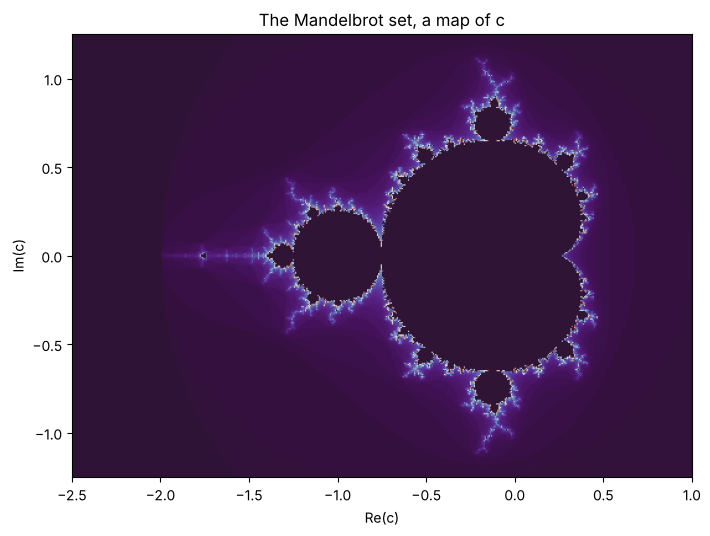

In [3]:
import matplotlib.pyplot as plt
from fractal_lab.palettes import MANDELBROT_CMAP

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(grid, cmap=MANDELBROT_CMAP, extent=[-2.5, 1.0, -1.25, 1.25],
          origin="lower")
ax.set_title("The Mandelbrot set, a map of c")
ax.set_xlabel("Re(c)")
ax.set_ylabel("Im(c)")
plt.show()

## Read the map

Pick a point on the map and you have picked a Julia set.

- Points **inside** the set give connected Julia sets.
- Points **outside** give dust.
- Points near the **boundary** give the most intricate Julia sets.

The cell below marks four values of `c` on the map and shows the
Julia set each one produces.

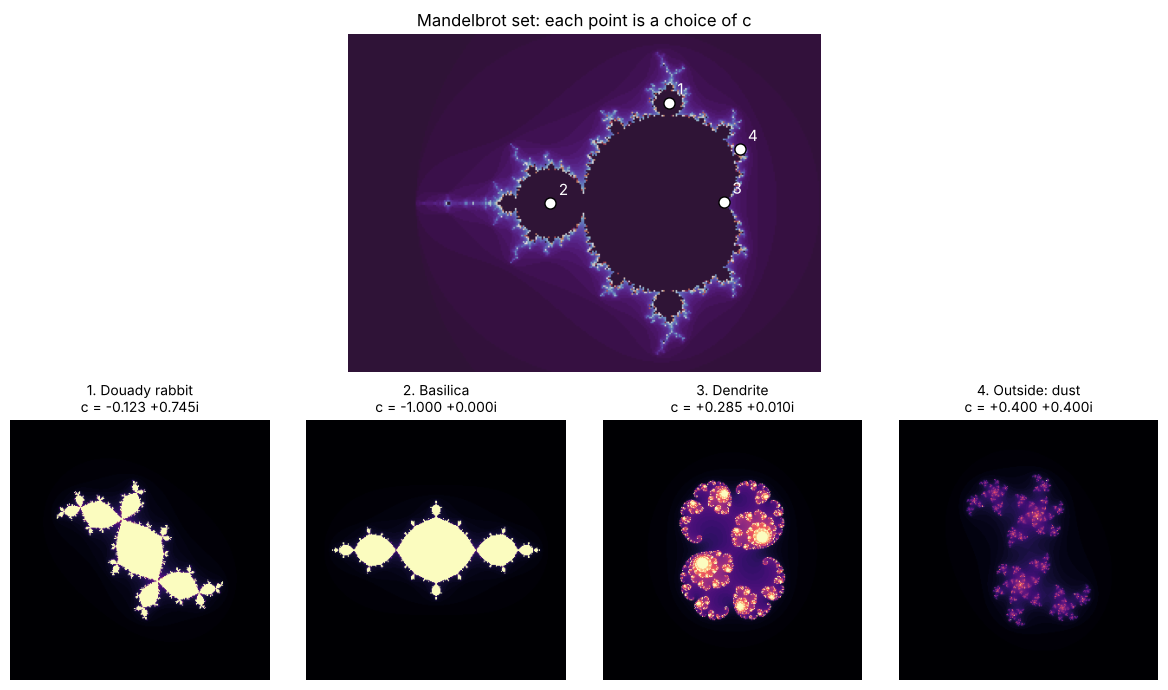

In [4]:
from fractal_lab import lessons

fig = lessons.mandelbrot_map()
plt.show()

## Now explore it yourself

In Jupyter this opens two sliders. Move `c` across the map and watch
the Julia set on the right respond. Cross the boundary of the set and
the Julia set shatters into dust.

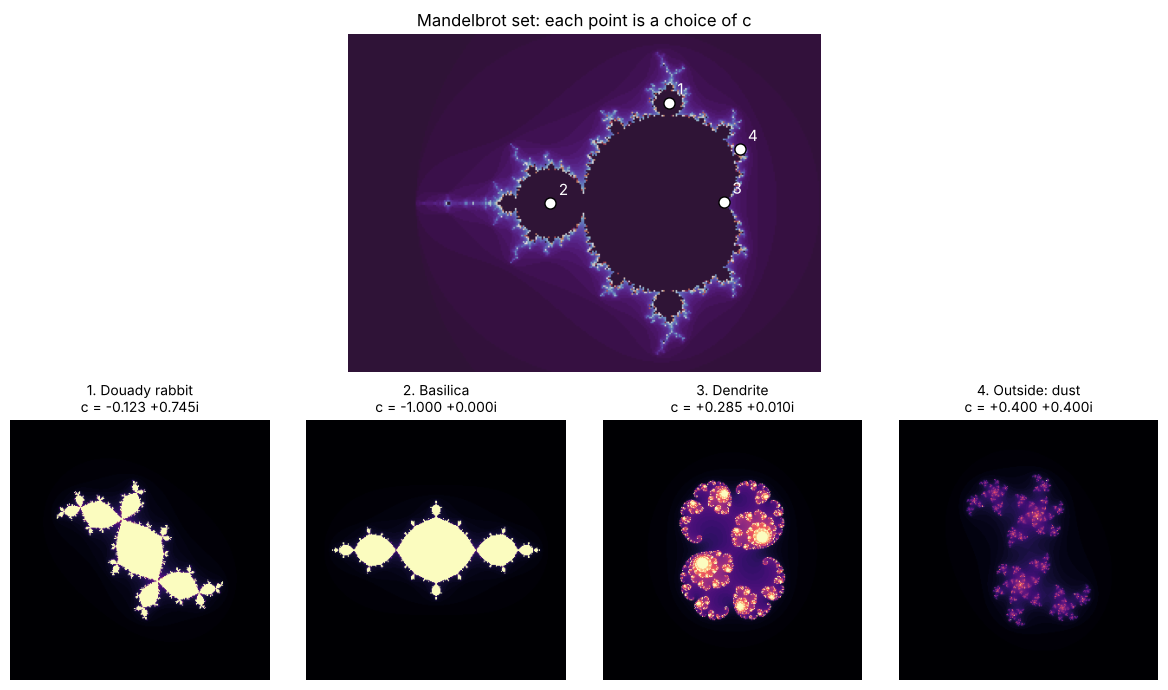

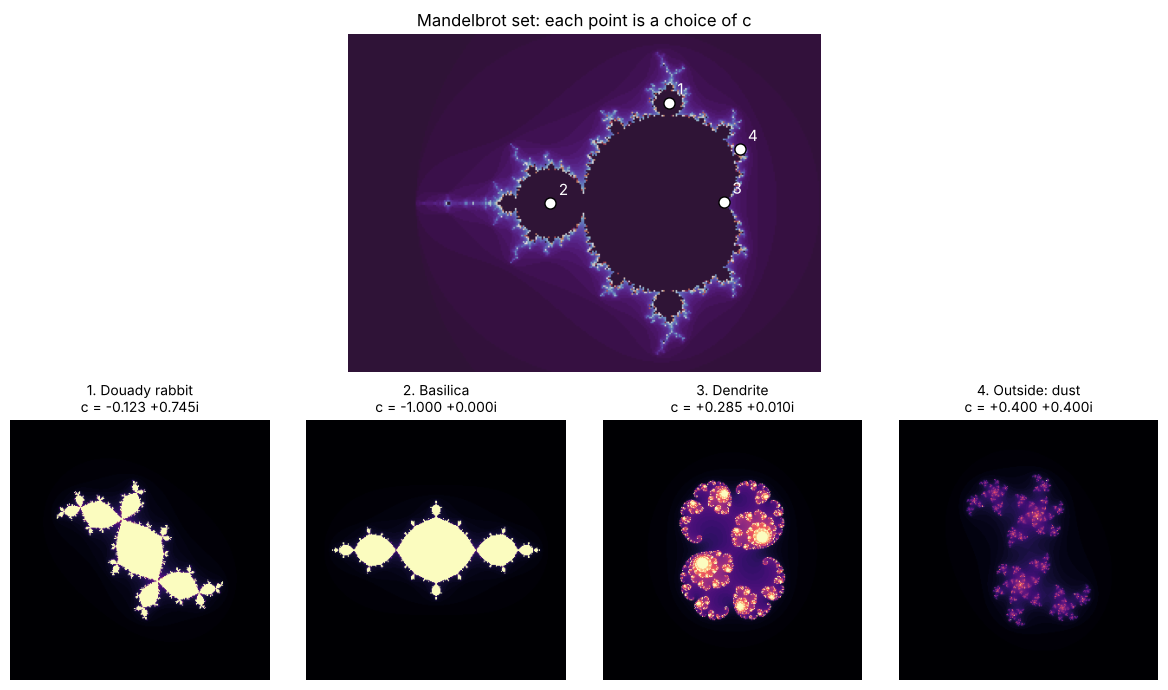

In [5]:
lessons.mandelbrot_map()

## Recap

- `c` lives in its own plane, separate from `z`.
- The Mandelbrot set is every `c` whose critical orbit stays bounded.
- A point's position on the map predicts the shape of its Julia set.

One map, infinitely many Julia sets.